In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

ROOT = "SARD1"
SPLITS = ["train", "valid", "test"]
os.makedirs("charts", exist_ok=True)

## 1. Read the labels
Each image has a `.txt` label file. Each line is one human box: `class cx cy w h` (values are 0-1, fraction of the 640x640 image).
An **empty** file means the image has no human.

In [ ]:
def read_boxes(label_file):
    with open(label_file) as f:
        lines = [l.split() for l in f.read().strip().splitlines() if l.strip()]
    return [tuple(map(float, l[1:5])) for l in lines]

boxes = {}   # split -> {file name: [boxes]}
for s in SPLITS:
    folder = f"{ROOT}/{s}/labels"
    boxes[s] = {f: read_boxes(f"{folder}/{f}") for f in os.listdir(folder)}

for s in SPLITS:
    print(s, "->", len(boxes[s]), "images")

train -> 4041 images
valid -> 1144 images
test -> 570 images


In [3]:
n_human = [sum(len(b) > 0 for b in boxes[s].values()) for s in SPLITS]
n_empty = [sum(len(b) == 0 for b in boxes[s].values()) for s in SPLITS]

for s, h, e in zip(SPLITS, n_human, n_empty):
    print(f"{s}: {h} with human, {e} empty ({e/(h+e):.1%} empty)")

train: 3470 with human, 571 empty (14.1% empty)
valid: 967 with human, 177 empty (15.5% empty)
test: 486 with human, 84 empty (14.7% empty)


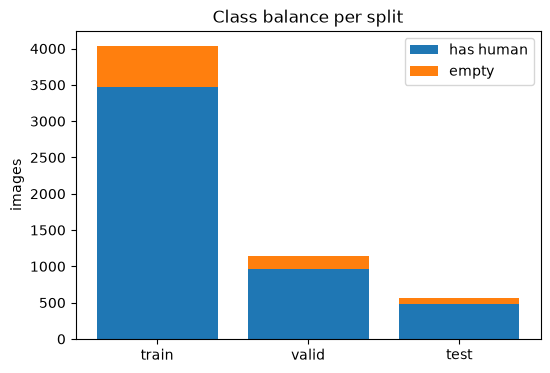

In [4]:
# Chart 1: stacked bar of human vs. empty images per split
x = np.arange(len(SPLITS))
plt.figure(figsize=(6, 4))
plt.bar(x, n_human, label="has human")
plt.bar(x, n_empty, bottom=n_human, label="empty")
plt.xticks(x, SPLITS)
plt.ylabel("images")
plt.title("Class balance per split")
plt.legend()
plt.show()

## 3. Label sanity check
A box is "bad" if it has zero size or sticks out of the image.

In [5]:
def is_bad(cx, cy, w, h):
    return (w <= 0 or h <= 0 or
            cx - w/2 < -0.01 or cy - h/2 < -0.01 or
            cx + w/2 > 1.01 or cy + h/2 > 1.01)

for s in SPLITS:
    all_boxes = [b for bs in boxes[s].values() for b in bs]
    n_bad = sum(is_bad(*b) for b in all_boxes)
    most = max(len(bs) for bs in boxes[s].values())
    print(f"{s}: {len(all_boxes)} boxes, max {most} per image, {n_bad} bad boxes")

train: 5229 boxes, max 7 per image, 0 bad boxes
valid: 1463 boxes, max 7 per image, 0 bad boxes
test: 732 boxes, max 7 per image, 0 bad boxes


## 4. Box sizes in pixels
Boxes are fractions of the image, so multiply by 640 to get pixels. We use the **train** split only.
This tells us how small the humans are, and therefore which patch size and window scales to use.

In [6]:
train_boxes = [b for bs in boxes["train"].values() for b in bs]
w = np.array([b[2] for b in train_boxes]) * 640
h = np.array([b[3] for b in train_boxes]) * 640

print("Width  px: min %.0f median %.0f mean %.0f max %.0f" % (w.min(), np.median(w), w.mean(), w.max()))
print("Height px: min %.0f median %.0f mean %.0f max %.0f" % (h.min(), np.median(h), h.mean(), h.max()))
print("Longer side percentiles (10/25/50/75/90):", np.percentile(np.maximum(w, h), [10, 25, 50, 75, 90]).round())

Width  px: min 1 median 36 mean 46 max 322
Height px: min 2 median 82 mean 95 max 478
Longer side percentiles (10/25/50/75/90): [ 48.  62.  86. 122. 164.]


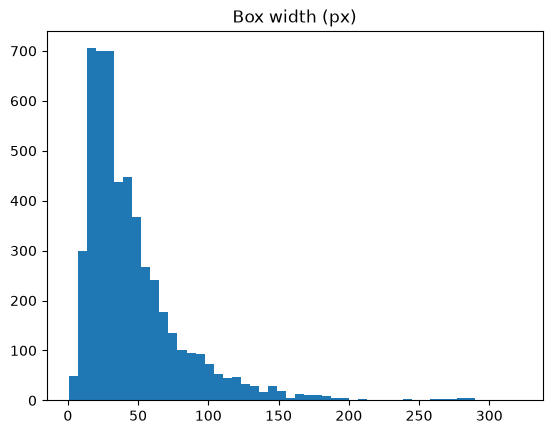

In [7]:
# Chart 2: box width
plt.hist(w, bins=50)
plt.title("Box width (px)")
plt.show()

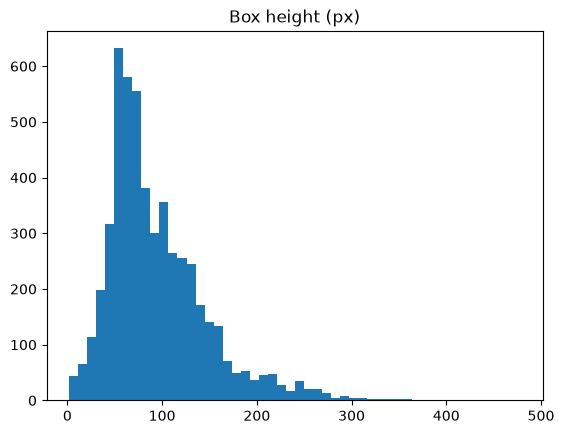

In [8]:
# Chart 3: box height
plt.hist(h, bins=50)
plt.title("Box height (px)")
plt.show()

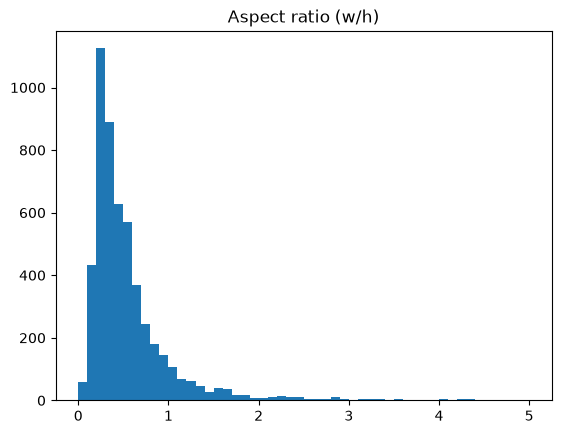

In [9]:
# Chart 4: aspect ratio (width / height). 1 = square, <1 = tall (standing), >1 = wide (lying down)
plt.hist(w / h, bins=50, range=(0, 5))
plt.title("Aspect ratio (w/h)")
plt.show()

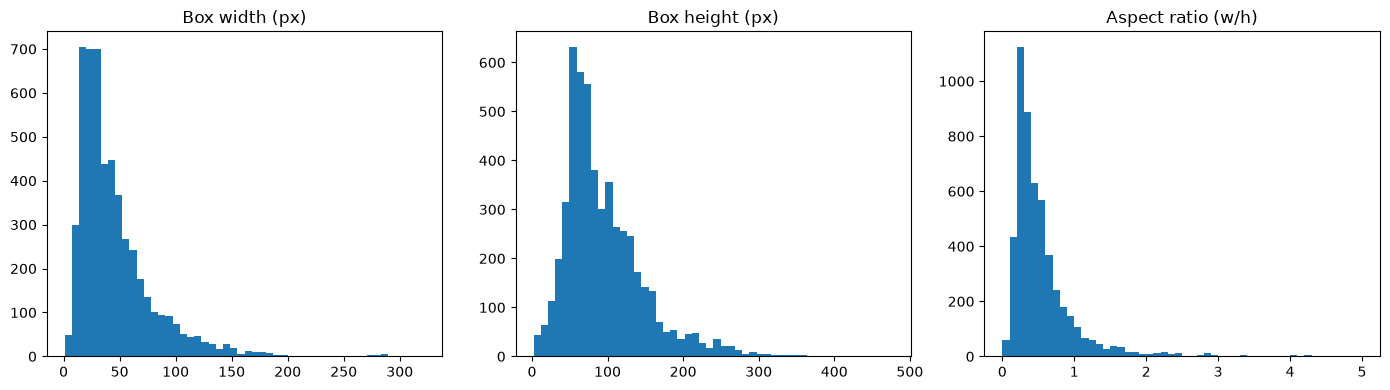

In [10]:
# The three size charts side by side, saved for the slides
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].hist(w, bins=50); ax[0].set_title("Box width (px)")
ax[1].hist(h, bins=50); ax[1].set_title("Box height (px)")
ax[2].hist(w / h, bins=50, range=(0, 5)); ax[2].set_title("Aspect ratio (w/h)")
plt.tight_layout()
plt.savefig("charts/box_sizes.png")
plt.show()

## 5. Leakage check: same photo in different splits?
The dataset was exported from Roboflow, which makes several augmented copies of each photo.
The original name is the part before `_jpg.rf.`. If an original appears in two splits, test results would be inflated.

In [11]:
originals = {s: {f.split("_jpg.rf.")[0] for f in boxes[s]} for s in SPLITS}

print("train & valid:", len(originals["train"] & originals["valid"]))
print("train & test :", len(originals["train"] & originals["test"]))
print("valid & test :", len(originals["valid"] & originals["test"]))
print(f"train has {len(boxes['train'])} files but only {len(originals['train'])} original photos")

train & valid: 0
train & test : 0
valid & test : 0
train has 4041 files but only 1387 original photos
